# Fase 4 — Procedência das checagens

**Detecção de notícias falsas em português e robustez frente à IA generativa**  
Alice Vitória Cordeiro França — IFPR Campus Paranaguá  
Tecnologia em Análise e Desenvolvimento de Sistemas

---

### O que este notebook faz

Identifica qual agência de checagem verificou cada notícia falsa, a partir do caminho do endereço de origem e não apenas do domínio — dentro de um mesmo domínio convivem a redação e a agência de checagem, e confundi-los atribuiria a verificação ao veículo errado. A distribuição resultante delimita a quais práticas de checagem os resultados do estudo se aplicam.

### Entradas

- `fakerecogna_bruto.csv`
- `dados/corpus_base.csv`

### Saídas de dados

- `dados/agencias.csv`

### Figuras geradas para o artigo

- `figuras/fig_agencias.png` — notícias falsas por agência de checagem de origem

Todas as figuras saem deste notebook, em PNG de 400 dpi e 15 cm de largura, prontas para entrar no artigo em escala 1:1. O padrão visual está no módulo `estilo_sbc.py`, gravado no Drive pela célula 2 e idêntico em todas as fases.

## 1. Ambiente

In [2]:
# Monta o Google Drive e fixa a estrutura de pastas do projeto.
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

A célula abaixo grava o módulo `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC — largura útil, corpo tipográfico, resolução e separação de luminância para impressão em preto e branco. Por ser o mesmo módulo nas oito fases, nenhuma figura do artigo sai fora do padrão.

In [3]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
"""
estilo_sbc - padrao visual unico para todas as figuras do artigo.

Cada decisao abaixo responde a uma exigencia concreta do template da SBC.

1. Largura de exatamente 15 cm, garantida no arquivo final. E a area util de
   texto do template em A4 com margens laterais de 3 cm. Nao basta pedir
   `figsize`: o `bbox_inches='tight'` do matplotlib recorta ou expande a
   figura conforme o tamanho dos rotulos, e o PNG sai com largura
   imprevisivel - entre 12 e 17 cm, nos testes. A funcao `salvar` normaliza:
   mede o resultado, completa com branco quando falta e reduz quando sobra,
   e grava a resolucao nos metadados do PNG. O Word e o LaTeX passam a
   inserir a imagem no tamanho fisico certo sem ajuste manual, e so por isso
   a afirmacao de escala 1:1 se sustenta.
2. Tipografia entre 9 e 10,5 pt no grafico. Em escala 1:1 isso fica
   proximo do corpo do texto (Times 12 pt): legivel, sem competir com ele.
3. 400 dpi em PNG. O minimo usual para impressao e 300 dpi.
4. Paleta azul / vermelhao / ambar, derivada de Okabe-Ito, que e a
   referencia de cores seguras para daltonismo em figuras cientificas. O par
   azul-laranja e o mais comum na literatura justamente por ser o que
   sobrevive as tres formas de daltonismo. As luminancias valem 0,27, 0,47 e
   0,71: o template preve avaliacao impressa, eventualmente em preto e
   branco, e cores de luminancia proxima colapsam no mesmo cinza.
5. Escala tipografica fechada, de T_PEQUENO a T_DESTAQUE. Toda figura usa
   esses cinco tamanhos e nenhum outro: tamanhos escolhidos caso a caso
   fazem o conjunto parecer montado por pessoas diferentes.
6. Nenhum texto dentro da area de dados. Rotulo de serie vai para a legenda
   abaixo do eixo, valor de referencia vai para a linha de apoio do titulo.
   Texto sobre os dados colide assim que os dados mudam - e o que fez a
   primeira versao destas figuras ficar ilegivel com o corpus real.
7. Moldura aberta (sem as linhas superior e direita), grade apenas no eixo
   de valores e rotulo numerico em cada elemento: o leitor le o valor em
   vez de estima-lo pela altura da barra.
8. Eixo de valores sempre a partir de zero nos graficos de barra. Quando a
   diferenca entre as series e pequena demais para aparecer, troca-se o
   grafico de barras por um dot plot - truncar o eixo exageraria a
   diferenca e seria enganoso.

Uso:
    from estilo_sbc import *
    destino('/content/drive/MyDrive/TCC/figuras')
    fig, ax = plt.subplots(figsize=(LARGURA, 7*CM))
    ...
    salvar(fig, 'fig_exemplo')
"""

import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

# ----------------------------------------------------------------- paleta
# Azul, vermelhao e ambar, da familia Okabe-Ito. O azul foi escurecido em
# relacao ao original para abrir distancia de luminancia dos outros dois e
# alcancar contraste de texto sobre branco.
AZUL    = '#1B4F72'   # serie primaria   (Regressao Logistica) - luminancia 0,27
LARANJA = '#D55E00'   # serie secundaria (Random Forest)       - luminancia 0,47
AMBAR   = '#E8B04B'   # serie terciaria  (BERTimbau)           - luminancia 0,71
VERDE   = '#117733'   # acento, so quando existe uma quarta serie
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

# Variantes escurecidas para TEXTO. A luminancia que separa as cores na
# impressao em cinza e justamente o que derruba o contraste delas sobre o
# branco: o vermelhao alcanca 3,9:1 e o ambar 1,9:1, abaixo do minimo de
# 4,5:1 que a WCAG pede para texto deste corpo. Preencher formas com a cor da
# serie e escrever com a variante escura resolve os dois lados.
AZUL_TEXTO    = AZUL       # 8,8:1
LARANJA_TEXTO = '#A64A00'  # 5,8:1
AMBAR_TEXTO   = '#8A6410'  # 5,1:1
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

# ------------------------------------------------------------ tipografia
# Escala fechada. Nenhuma figura inventa um tamanho fora destes cinco.
T_PEQUENO  = 8.0    # nota de rodape dentro da figura, anotacao secundaria
T_CORPO    = 9.0    # eixos, legenda, linha de apoio do titulo
T_ROTULO   = 9.5    # valor escrito sobre barra ou ponto
T_TITULO   = 10.5   # titulo da figura e de cada painel
T_DESTAQUE = 13.0   # numero isolado em painel de sintese


def legivel(cor):
    """Variante da cor com contraste suficiente para texto sobre branco."""
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}

# Comeca num cinza muito claro, nao em branco puro: com branco as celulas
# de valor zero somem e a matriz perde a forma de matriz.
MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])

# ----------------------------------------------------------------- medidas
CM = 1 / 2.54
LARGURA = 15 * CM          # largura total da area de texto do template
LARGURA_MEIA = 7.2 * CM    # duas figuras lado a lado

# ----------------------------------------------------------------- tipografia
# DejaVu Sans vem instalada no Colab e cobre toda a acentuacao do portugues,
# mas tem apenas dois pesos: normal e negrito. Pedir 'semibold' faz o
# matplotlib emitir aviso e cair no negrito de qualquer forma, por isso os
# pesos aqui sao sempre 'normal' ou 'bold'. Se uma familia com mais pesos
# estiver instalada no ambiente, ela e usada - sem exigir instalacao nenhuma.
_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

# ----------------------------------------------------------------- rcParams
mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})

# ----------------------------------------------------------------- destino
_destino = Path('.')


def destino(pasta):
    """Define a pasta onde salvar() grava as figuras."""
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    """Grava a figura em PNG com largura fisica exata e dpi nos metadados.

    O matplotlib com bbox_inches='tight' devolve larguras diferentes a cada
    figura, conforme o tamanho dos rotulos. Aqui o resultado e normalizado
    para `largura_cm`: se ficou estreito, completa-se com branco, o que
    preserva o corpo das letras; se ficou largo, reduz-se a imagem inteira,
    e a reducao aplicada e informada na saida. Passe largura_cm=None para
    gravar sem normalizar.
    """
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho


# ----------------------------------------------------------------- helpers
def br(texto):
    """Converte um numero ja formatado para a convencao brasileira.

    Troca o separador decimal por virgula e o de milhar por ponto. Um artigo
    em portugues com "97.40%" no grafico e "97,40%" no texto nao passa pela
    revisao, entao a conversao fica embutida nos helpers de rotulo e nos
    formatadores de eixo - nao depende de lembrar caso a caso.
    """
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    """Percentual na convencao brasileira: pct(0.974, 2) -> '97,40%'."""
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    """Inteiro com separador de milhar: mil(11902) -> '11.902'."""
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    """Grade horizontal apenas (para barras verticais e linhas)."""
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    """Grade vertical apenas (para barras horizontais)."""
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    """Eixo numerico comum, tambem com virgula decimal."""
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    """Eixo percentual com folga no topo sem inventar marcas acima do maximo.

    Abrir espaco apenas com set_ylim faz o matplotlib desenhar marcas de 110%
    ou 120% num eixo de acuracia, o que nao existe. Aqui a folga e so espaco
    em branco: as marcas param no maximo real.
    """
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    """Escreve o valor acima de cada barra vertical."""
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    """Escreve o valor a direita de cada barra horizontal."""
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    """Reduz o corpo de um conjunto de textos ate o mais largo caber.

    Mede a largura real de cada texto na figura renderizada, em vez de
    confiar numa estimativa por numero de caracteres - a largura depende da
    fonte, do peso e de quais letras sao. O mesmo tamanho e aplicado a todos
    os textos do conjunto: encolher so o que transborda deixaria um rotulo
    menor que os vizinhos, o que aparece mais do que o problema original.
    """
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    """Legenda centralizada abaixo do eixo, fora da area de dados.

    Posicao unica para todas as figuras do artigo, por dois motivos. O
    primeiro e consistencia: legenda ora dentro, ora fora, faz o conjunto
    parecer montado aos pedacos. O segundo e que legenda dentro do grafico
    so fica livre por acaso - ela nao sabe onde estao os dados, e basta o
    corpus mudar para ela cair em cima deles.
    """
    # O afastamento e calculado em pontos e so depois convertido para
    # fracao do eixo. Usar uma fracao fixa afasta a legenda de forma
    # diferente em cada figura - num grafico de barras horizontais, alto, a
    # mesma fracao joga a legenda muito mais para baixo do que num grafico
    # baixo, e em alguns casos ela sobe por cima do rotulo do eixo.
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    """Legenda abaixo do eixo montada a partir de (rotulo, cor).

    Para graficos cujos artistas nao carregam rotulo - area empilhada,
    histograma desenhado em duas passagens, barras coloridas uma a uma.
    """
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    """Titulo em duas linhas: a afirmacao e, abaixo, a leitura de apoio.

    A linha de apoio e desenhada como anotacao acima do eixo, entao o
    afastamento do titulo precisa acomoda-la - com o `pad` padrao os dois
    se sobrepoem.
    """
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    """Afasta rotulos proximos demais para que nao se sobreponham.

    Devolve posicoes verticais na mesma unidade dos valores, preservando a
    ordem original. Usada quando varias series terminam em valores vizinhos:
    sem isso os rotulos se empilham e nenhum fica legivel.
    """
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    """Abre espaco no topo para os rotulos nao encostarem na borda."""
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    """Matriz de confusao 2x2 com contagem e percentual por celula."""
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    """Barras agrupadas. `series` e uma lista de (nome, valores, cor)."""
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [4]:
# Copia o modulo para o Drive (fica versionado junto com o projeto) e importa.
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *      # noqa: F401,F403
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [5]:
# Os arquivos podem estar em TCC/ ou em TCC/dados/; procura nos dois.

def arquivo(*nomes):
    """Primeiro dos nomes que existir em dados/ ou na raiz."""
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    """Resolve o nome real de uma coluna a partir de varios candidatos."""
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    """Todos os CSV sob a pasta do projeto, com contagem de linhas e colunas."""
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    """Inventário dos CSV da pasta do projeto."""
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    """Acha um CSV pelo nome e, falhando isso, pelas colunas."""
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    """(pasta, data, convencao) de cada modelo salvo sob o projeto.

    A convencao vem de convencao_rotulo.json, gravado pela Fase 5: sem ela
    nao da para saber se o rotulo 1 do modelo significa falsa ou verdadeira.
    """
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    """Pasta do BERTimbau ajustado que declare a convencao de rotulo pedida.

    Escolher por uma lista fixa de nomes nao distingue o modelo desta
    execucao de um modelo antigo salvo no mesmo caminho, e um modelo
    treinado sob a convencao oposta acerta menos que o acaso.
    """
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    """Carrega o spaCy português uma vez por sessão."""
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    """Reduz cada texto à sequência de lemas, como o corpus foi distribuído."""
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    """Fração de tokens alfabéticos que já coincidem com o próprio lema.

    Mede o quanto um conjunto já está na forma lematizada: o corpus fica
    acima de 0,90 e o português corrente, perto de 0,60.
    """
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Identificação da agência

A ordem dos testes importa: `/comprova/` e `/confere/` aparecem dentro de domínios de grandes veículos, então precisam ser testados antes do domínio genérico. Um teste só por domínio atribuiria ao UOL o que é do UOL Confere.

In [6]:
df = pd.read_csv(arquivo('corpus_base.csv'))

# O endereço já foi gravado em corpus_base.csv pela Fase 1, portanto é dele
# que se lê: reabrir o arquivo bruto exigiria realinhar os índices e abriria
# espaço para atribuir a checagem de uma notícia a outra.
if 'url' in df.columns:
    enderecos = df['url']
else:
    bruto = pd.read_csv(arquivo('fakerecogna_bruto.csv', 'FakeRecogna.csv'))
    if 'indice_origem' in df.columns:
        bruto = bruto.loc[df['indice_origem'].to_numpy()].reset_index(drop=True)
    elif len(bruto) != len(df):
        raise ValueError('Tamanhos incompatíveis. Rode a Fase 1 novamente.')
    enderecos = bruto[coluna(bruto, 'url', 'link', 'fonte')]

def identificar_fonte(url):
    if pd.isna(url):
        return 'Não identificado'
    url = str(url).lower()
    if 'projetocomprova' in url or '/comprova/' in url:   return 'Projeto Comprova'
    if '/confere/' in url:                                return 'UOL Confere'
    if 'boatos.org' in url:                               return 'Boatos.org'
    if 'aosfatos' in url:                                 return 'Aos Fatos'
    if 'e-farsas' in url:                                 return 'E-farsas'
    if 'checamos.afp' in url or 'afp-brasil' in url:      return 'AFP Checamos'
    if 'fato-ou-fake' in url:                             return 'Fato ou Fake (G1)'
    if 'estadao' in url and 'verifica' in url:            return 'Estadão Verifica'
    if 'lupa' in url:                                     return 'Agência Lupa'
    if 'g1.globo.com' in url:                             return 'G1'
    if 'extra.globo.com' in url:                          return 'Extra'
    if 'gov.br' in url:                                   return 'Ministério da Saúde'
    if 'uol.com.br' in url:                               return 'UOL'
    return 'Outra fonte (verificar)'

tmp = pd.DataFrame({'classe': df['classe'].values,
                    'fonte': enderecos.map(identificar_fonte).values})
falsas = tmp[tmp['classe'] == 'Falsa']
contagem = falsas['fonte'].value_counts()
contagem.rename_axis('agencia').rename('noticias').to_csv(DADOS / 'agencias.csv')
print(contagem.to_string())


fonte
Boatos.org           2484
Fato ou Fake (G1)    1184
E-farsas              804
Projeto Comprova      674
AFP Checamos          503
UOL Confere           284
UOL                    18


## 5. Figura — concentração por agência

Barras horizontais ordenadas por volume. As agências que respondem individualmente por pelo menos 5% das notícias falsas aparecem na cor principal; as demais em cinza, porque com poucas dezenas de registros não se sustenta afirmação sobre a prática daquela agência. A figura serve exatamente para marcar esse limite de validade no artigo.

[figura] fig_agencias.png               15.0 x 7.2 cm  (reduzida 18.0%)


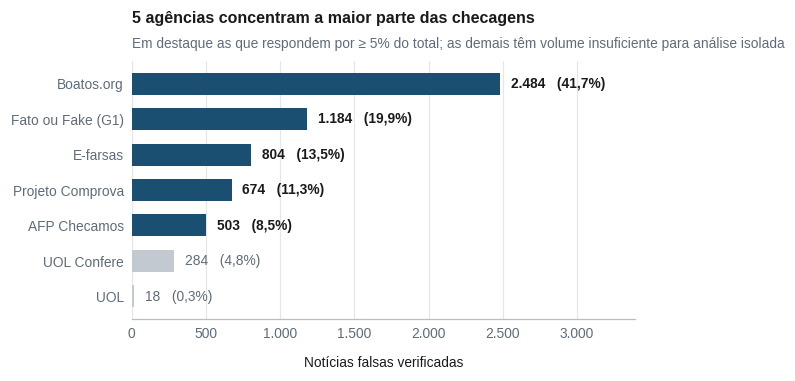

In [7]:
contagem = pd.read_csv(arquivo('agencias.csv'), index_col=0)['noticias']
contagem = contagem.sort_values()
prop = contagem / contagem.sum()
LIMITE = 0.05
cores = [AZUL if p >= LIMITE else NEUTRO for p in prop]

fig, ax = plt.subplots(figsize=(LARGURA, 0.62 * CM * len(contagem) + 3.4 * CM))
barras = ax.barh(contagem.index, contagem.values, color=cores, height=0.62)
for b, n, p in zip(barras, contagem.values, prop.values):
    ax.annotate(mil(n) + '   (' + pct(p, 1) + ')',
                xy=(n, b.get_y() + b.get_height() / 2), xytext=(7, 0),
                textcoords='offset points', ha='left', va='center',
                fontsize=T_CORPO, color=TEXTO if p >= LIMITE else SUAVE,
                fontweight='bold' if p >= LIMITE else 'normal')

robustas = int((prop >= LIMITE).sum())
grade_x(ax)
eixo_milhar(ax, 'x')
folga(ax, 'x', 0.30)
ax.set_xlabel('Notícias falsas verificadas')
titulo(ax, '{} agências concentram a maior parte das checagens'.format(robustas),
       'Em destaque as que respondem por ≥ 5% do total; as demais têm volume '
       'insuficiente para análise isolada')
salvar(fig, 'fig_agencias')
plt.show()


> **Limite de validade.** O que o estudo observa é o comportamento dos modelos sobre notícias falsas verificadas por essas agências, no período coberto pelo corpus. Generalizar para desinformação não verificada, ou para agências ausentes da base, extrapola os dados.